<a href="https://colab.research.google.com/github/Ridhman07/IP-Lab-Assignments/blob/main/Assignment%206.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_586/275493474.py:40: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axes[1, 0].hist(src_img.ravel(), 256, [0, 256], color='black'); axes[1, 0].set_title("Input Hist")
/tmp/ipykernel_586/275493474.py:41: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axes[1, 1].hist(equalized_img.ravel(), 256, [0, 256], color='black'); axes[1, 1].set_title("Equalized Hist")
/tmp/ipykernel_586/275493474.py:42: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axes[1, 2].hist(ref_img.ravel(), 256, [0, 256], color='black'); axes[1, 2].set_title("Reference Hist")
/tmp/ipykernel_586/275493474.py:43: MatplotlibDeprecationWarning: Passing the ra

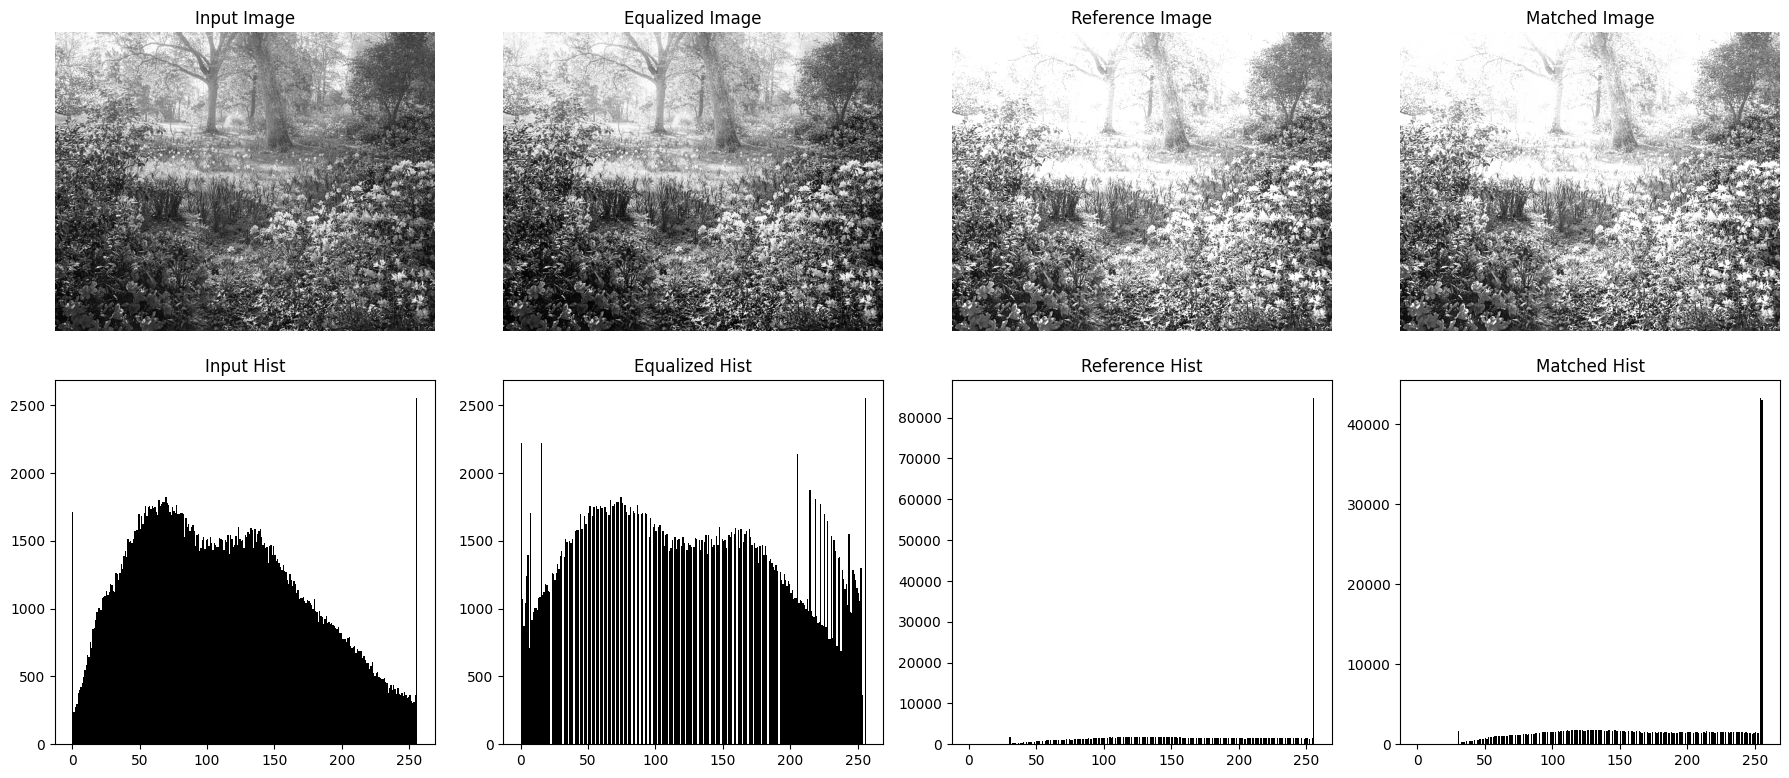

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

src_path = "/content/image.jpg"

# Read source image
src_img = cv2.imread(src_path, cv2.IMREAD_GRAYSCALE)

# Create a reference image for matching (or replace with cv2.imread of a second image)
ref_img = cv2.convertScaleAbs(src_img, alpha=1.5, beta=30)

# Helper function to compute CDF
def get_cdf(img):
    hist, _ = np.histogram(img.flatten(), 256, [0, 256])
    cdf = hist.cumsum()
    return cdf / cdf[-1]

# 1. Histogram Equalization
equalized_img = cv2.equalizeHist(src_img)

# 2. Histogram Matching via CDF
src_cdf = get_cdf(src_img)
ref_cdf = get_cdf(ref_img)

mapping = np.zeros(256, dtype=np.uint8)
for i in range(256):
    mapping[i] = np.argmin(np.abs(ref_cdf - src_cdf[i]))

matched_img = mapping[src_img]

# Display outputs
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

axes[0, 0].imshow(src_img, cmap='gray'); axes[0, 0].set_title("Input Image"); axes[0, 0].axis('off')
axes[0, 1].imshow(equalized_img, cmap='gray'); axes[0, 1].set_title("Equalized Image"); axes[0, 1].axis('off')
axes[0, 2].imshow(ref_img, cmap='gray'); axes[0, 2].set_title("Reference Image"); axes[0, 2].axis('off')
axes[0, 3].imshow(matched_img, cmap='gray'); axes[0, 3].set_title("Matched Image"); axes[0, 3].axis('off')

axes[1, 0].hist(src_img.ravel(), 256, [0, 256], color='black'); axes[1, 0].set_title("Input Hist")
axes[1, 1].hist(equalized_img.ravel(), 256, [0, 256], color='black'); axes[1, 1].set_title("Equalized Hist")
axes[1, 2].hist(ref_img.ravel(), 256, [0, 256], color='black'); axes[1, 2].set_title("Reference Hist")
axes[1, 3].hist(matched_img.ravel(), 256, [0, 256], color='black'); axes[1, 3].set_title("Matched Hist")

plt.tight_layout()
plt.show()